# CITE-seq: CD9⁺ vs CD9⁻ macrophage surface protein

Supp 7F. Macrophages are split by CD9 transcript detection (CD9 RNA > 0) within RNA-annotated macrophages (AUCell myeloid labels from `01_aucell_annotation.R`; DCs and neutrophils removed).

1. Keep cells whose RNA and protein lineage calls agree; CLR-normalise the ADT matrix.
2. Normalise myeloid RNA and label CD9⁺ / CD9⁻ macrophages.
3. Compare every protein between CD9⁺ and CD9⁻ macrophages (two-sided Mann-Whitney U, Benjamini-Hochberg) and compute Cohen's d; keep proteins with adjusted P ≤ 0.1 and |d| ≥ 0.2.
4. Heatmap of the retained proteins (`cd9_mac_top_diff_prs.pdf`) and split violins of the top 12 with Cohen's d (Supp 7F).

In [3]:
import pandas as pd

In [4]:
rna_counts = pd.read_csv('/share/fsmresfiles/UC/Schipma/cite-seq_combined/annotation_for_cosmx/third_round/RNA_raw_counts.csv')
pr_counts=pd.read_csv('/share/fsmresfiles/UC/Schipma/cite-seq_combined/annotation_for_cosmx/third_round/protein_raw_counts.csv')
anno=pd.read_csv('/share/fsmresfiles/UC/Schipma/cite-seq_combined/annotation_for_cosmx/third_round/annotation_table.csv')

In [11]:
rna_counts

,Unnamed: 0,MIR1302-2HG,FAM138A,OR4F5,AL627309.1,AL627309.3,AL627309.2,AL627309.5,AL627309.4,AP006222.2,...,AC133551.1,AC136612.1,AC136616.1,AC136616.3,AC136616.2,AC141272.1,AC023491.2,AC007325.1,AC007325.4,AC007325.2
0,AAACCTGCAATCCGAT-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,AAACCTGCAGAAGCAC-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,AAACCTGGTATATCCG-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,AAACCTGGTCACCTAA-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,AAACCTGGTCGGCATC-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57929,TTTGTCAGTACCGTTA-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57930,TTTGTCAGTCTTGATG-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57931,TTTGTCAGTGTGCGTC-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57932,TTTGTCATCCGATATG-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [57]:
rna_counts['CD9'].describe()

count    57934.000000
mean         0.306659
std          0.955791
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         20.000000
Name: CD9, dtype: float64

In [6]:
pr_counts

,Unnamed: 0,anti-human_CD86,anti-human_CD274_B7-H1_PD-L1,anti-human_CD270_HVEM_TR2,anti-human_CD155_PVR,anti-human_CD112_Nectin-2,anti-human_CD47,anti-human_CD48,anti-human_CD40,anti-human_CD154,...,anti-human_CD85j_ILT2,anti-human_CD23,anti-human_Ig_light_chain_L,anti-human_CD328_Siglec-7,anti-human_GPR56,anti-human_HLA-E,anti-human_CD82,anti-human_CD101_BB27,anti-human_CD88_C5aR,anti-human_CD224
0,AAACCTGCAATCCGAT-1-0,1.0,2.0,5.0,1.0,4.0,29.0,34.0,6.0,0.0,...,3.0,2.0,5.0,0.0,0.0,4.0,25.0,0.0,1.0,5.0
1,AAACCTGCAGAAGCAC-1-0,0.0,0.0,28.0,9.0,6.0,20.0,2.0,1.0,6.0,...,1.0,5.0,3.0,0.0,0.0,7.0,67.0,2.0,3.0,77.0
2,AAACCTGGTATATCCG-1-0,1.0,1.0,3.0,16.0,4.0,45.0,2.0,0.0,4.0,...,1.0,5.0,2.0,0.0,1.0,1.0,22.0,0.0,2.0,34.0
3,AAACCTGGTCACCTAA-1-0,0.0,2.0,5.0,6.0,5.0,24.0,2.0,1.0,1.0,...,1.0,2.0,3.0,0.0,0.0,1.0,26.0,0.0,1.0,7.0
4,AAACCTGGTCGGCATC-1-0,0.0,5.0,20.0,5.0,6.0,40.0,1.0,2.0,9.0,...,2.0,10.0,2.0,0.0,2.0,4.0,45.0,0.0,4.0,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57929,TTTGTCAGTACCGTTA-1-11,7.0,9.0,9.0,8.0,10.0,147.0,178.0,7.0,20.0,...,7.0,23.0,12.0,4.0,3.0,9.0,48.0,5.0,18.0,50.0
57930,TTTGTCAGTCTTGATG-1-11,0.0,3.0,3.0,0.0,5.0,54.0,41.0,1.0,4.0,...,1.0,3.0,1.0,0.0,0.0,8.0,15.0,0.0,6.0,11.0
57931,TTTGTCAGTGTGCGTC-1-11,1.0,7.0,4.0,3.0,6.0,28.0,14.0,9.0,4.0,...,4.0,5.0,4.0,6.0,0.0,5.0,12.0,0.0,4.0,22.0
57932,TTTGTCATCCGATATG-1-11,0.0,2.0,3.0,2.0,5.0,193.0,96.0,5.0,6.0,...,15.0,6.0,43.0,4.0,1.0,4.0,17.0,3.0,9.0,45.0


In [7]:
sorted(pr_counts.columns.tolist())

['Armenian_Hamster_IgG_Isotype_Ctrl',
 'Mouse_IgG1_K_isotype_Ctrl',
 'Mouse_IgG2a_K_isotype_Ctrl',
 'Mouse_IgG2b_K_isotype_Ctrl',
 'Rat_IgG1_K_isotype_Ctrl',
 'Rat_IgG2a_K_Isotype_Ctrl',
 'Rat_IgG2b_K_Isotype_Ctrl',
 'Unnamed: 0',
 'anti-human-mouse-rat_CD278_ICOS',
 'anti-human-mouse_CD49f',
 'anti-human-mouse_integrin_B7',
 'anti-human_CD101_BB27',
 'anti-human_CD103_Integrin_aE',
 'anti-human_CD105',
 'anti-human_CD107a_LAMP-1',
 'anti-human_CD112_Nectin-2',
 'anti-human_CD119_IFN-g_R_a_chain',
 'anti-human_CD11a',
 'anti-human_CD11b',
 'anti-human_CD11c',
 'anti-human_CD122_IL-2RB',
 'anti-human_CD123',
 'anti-human_CD124_IL-4Ra',
 'anti-human_CD127_IL-7Ra',
 'anti-human_CD13',
 'anti-human_CD134_OX40',
 'anti-human_CD137_4-1BB',
 'anti-human_CD14',
 'anti-human_CD141_Thrombomodulin',
 'anti-human_CD146',
 'anti-human_CD152_CTLA-4',
 'anti-human_CD154',
 'anti-human_CD155_PVR',
 'anti-human_CD158_KIR2DL1-S1-S3-S5',
 'anti-human_CD158b_KIR2DL2-L3_NKAT2',
 'anti-human_CD158e1_KIR3DL1

In [8]:
anno

,Unnamed: 0,dataset,RNA_annotation,Protein_annotation
0,AAACCTGCAATCCGAT-1-0,I0281,b,b/undiff mixed
1,AAACCTGCAGAAGCAC-1-0,I0281,epithelial,epithelial
2,AAACCTGGTATATCCG-1-0,I0281,epithelial,epithelial
3,AAACCTGGTCACCTAA-1-0,I0281,epithelial,epithelial
4,AAACCTGGTCGGCATC-1-0,I0281,epithelial,epithelial
...,...,...,...,...
57929,TTTGTCAGTACCGTTA-1-11,IBD_I0334_I0337_2,tnk,tnk
57930,TTTGTCAGTCTTGATG-1-11,IBD_I0334_I0337_2,tnk,tnk
57931,TTTGTCAGTGTGCGTC-1-11,IBD_I0334_I0337_2,myeloid,myeloid
57932,TTTGTCATCCGATATG-1-11,IBD_I0334_I0337_2,plasma,plasma


In [13]:
anno['dataset'].unique()

array(['I0281', 'I0327', 'I0328_1', 'I0328_2', 'I0282', 'I0283',
       'I0287_colon', 'I0287_ileum', 'I0288', 'I0289',
       'IBD_I0334_I0337_1', 'IBD_I0334_I0337_2'], dtype=object)

In [14]:
anno[anno['Protein_annotation']=='myeloid']

,Unnamed: 0,dataset,RNA_annotation,Protein_annotation
135,AACTCAGGTGTGCGTC-1-0,I0281,myeloid,myeloid
175,AACTGGTCAGGTCGTC-1-0,I0281,myeloid,myeloid
251,AAGGTTCTCCTTGCCA-1-0,I0281,myeloid,myeloid
268,AATCCAGAGCTACCGC-1-0,I0281,myeloid,myeloid
334,ACACCGGTCGAGCCCA-1-0,I0281,myeloid,myeloid
...,...,...,...,...
57830,TTGCCGTCATTCTTAC-1-11,IBD_I0334_I0337_2,myeloid,myeloid
57842,TTGGAACAGTGTTGAA-1-11,IBD_I0334_I0337_2,myeloid,myeloid
57844,TTGGAACCAGCTATTG-1-11,IBD_I0334_I0337_2,myeloid,myeloid
57912,TTTGCGCTCACCTTAT-1-11,IBD_I0334_I0337_2,myeloid,myeloid


In [15]:
good_cell=[]
for i,j,k in zip (anno['Unnamed: 0'].tolist(),anno['RNA_annotation'].tolist(),anno['Protein_annotation'].tolist()):
    if j ==k:
        good_cell.append(i)

In [16]:
len(good_cell)

47080

In [17]:
good_anno = anno[anno['Unnamed: 0'].isin(good_cell)]

In [18]:
good_anno

,Unnamed: 0,dataset,RNA_annotation,Protein_annotation
1,AAACCTGCAGAAGCAC-1-0,I0281,epithelial,epithelial
2,AAACCTGGTATATCCG-1-0,I0281,epithelial,epithelial
3,AAACCTGGTCACCTAA-1-0,I0281,epithelial,epithelial
4,AAACCTGGTCGGCATC-1-0,I0281,epithelial,epithelial
6,AAACCTGTCACGACTA-1-0,I0281,plasma,plasma
...,...,...,...,...
57927,TTTGTCAAGGGCTTCC-1-11,IBD_I0334_I0337_2,tnk,tnk
57929,TTTGTCAGTACCGTTA-1-11,IBD_I0334_I0337_2,tnk,tnk
57930,TTTGTCAGTCTTGATG-1-11,IBD_I0334_I0337_2,tnk,tnk
57931,TTTGTCAGTGTGCGTC-1-11,IBD_I0334_I0337_2,myeloid,myeloid


In [19]:
good_anno['RNA_annotation'].value_counts()

RNA_annotation
epithelial     19962
tnk            16524
plasma          8626
myeloid         1450
granulocyte      518
Name: count, dtype: int64

In [20]:
good_rna= rna_counts[rna_counts['Unnamed: 0'].isin(good_cell)]
good_pr= pr_counts[pr_counts['Unnamed: 0'].isin(good_cell)]

In [21]:
good_rna

,Unnamed: 0,MIR1302-2HG,FAM138A,OR4F5,AL627309.1,AL627309.3,AL627309.2,AL627309.5,AL627309.4,AP006222.2,...,AC133551.1,AC136612.1,AC136616.1,AC136616.3,AC136616.2,AC141272.1,AC023491.2,AC007325.1,AC007325.4,AC007325.2
1,AAACCTGCAGAAGCAC-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,AAACCTGGTATATCCG-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,AAACCTGGTCACCTAA-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,AAACCTGGTCGGCATC-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,AAACCTGTCACGACTA-1-0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57927,TTTGTCAAGGGCTTCC-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57929,TTTGTCAGTACCGTTA-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57930,TTTGTCAGTCTTGATG-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57931,TTTGTCAGTGTGCGTC-1-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
good_pr

,Unnamed: 0,anti-human_CD86,anti-human_CD274_B7-H1_PD-L1,anti-human_CD270_HVEM_TR2,anti-human_CD155_PVR,anti-human_CD112_Nectin-2,anti-human_CD47,anti-human_CD48,anti-human_CD40,anti-human_CD154,...,anti-human_CD85j_ILT2,anti-human_CD23,anti-human_Ig_light_chain_L,anti-human_CD328_Siglec-7,anti-human_GPR56,anti-human_HLA-E,anti-human_CD82,anti-human_CD101_BB27,anti-human_CD88_C5aR,anti-human_CD224
1,AAACCTGCAGAAGCAC-1-0,0.0,0.0,28.0,9.0,6.0,20.0,2.0,1.0,6.0,...,1.0,5.0,3.0,0.0,0.0,7.0,67.0,2.0,3.0,77.0
2,AAACCTGGTATATCCG-1-0,1.0,1.0,3.0,16.0,4.0,45.0,2.0,0.0,4.0,...,1.0,5.0,2.0,0.0,1.0,1.0,22.0,0.0,2.0,34.0
3,AAACCTGGTCACCTAA-1-0,0.0,2.0,5.0,6.0,5.0,24.0,2.0,1.0,1.0,...,1.0,2.0,3.0,0.0,0.0,1.0,26.0,0.0,1.0,7.0
4,AAACCTGGTCGGCATC-1-0,0.0,5.0,20.0,5.0,6.0,40.0,1.0,2.0,9.0,...,2.0,10.0,2.0,0.0,2.0,4.0,45.0,0.0,4.0,24.0
6,AAACCTGTCACGACTA-1-0,1.0,4.0,8.0,5.0,4.0,129.0,130.0,2.0,9.0,...,3.0,4.0,4.0,0.0,1.0,2.0,15.0,1.0,2.0,26.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57927,TTTGTCAAGGGCTTCC-1-11,0.0,2.0,10.0,0.0,7.0,37.0,85.0,5.0,13.0,...,5.0,7.0,11.0,16.0,2.0,6.0,21.0,4.0,9.0,14.0
57929,TTTGTCAGTACCGTTA-1-11,7.0,9.0,9.0,8.0,10.0,147.0,178.0,7.0,20.0,...,7.0,23.0,12.0,4.0,3.0,9.0,48.0,5.0,18.0,50.0
57930,TTTGTCAGTCTTGATG-1-11,0.0,3.0,3.0,0.0,5.0,54.0,41.0,1.0,4.0,...,1.0,3.0,1.0,0.0,0.0,8.0,15.0,0.0,6.0,11.0
57931,TTTGTCAGTGTGCGTC-1-11,1.0,7.0,4.0,3.0,6.0,28.0,14.0,9.0,4.0,...,4.0,5.0,4.0,6.0,0.0,5.0,12.0,0.0,4.0,22.0


In [23]:
import numpy as np
import pandas as pd
from scipy.stats import gmean

def clr_normalization(adt_df):
    """
    Perform CLR normalization on an ADT protein expression matrix.
    
    Parameters:
        adt_df (pd.DataFrame): Rows are cells, columns are proteins.
    
    Returns:
        pd.DataFrame: CLR-transformed protein expression matrix.
    """
    # Replace zeros with a small value to avoid log(0)
    adt_df = adt_df.replace(0, np.nan)  
    adt_df = adt_df.fillna(adt_df.min().min() * 0.01)  
    
    # Compute geometric mean per cell (across proteins)
    geometric_means = gmean(adt_df, axis=1)
    
    # Apply CLR transformation: log(expression / geometric mean)
    clr_transformed = np.log(adt_df.div(geometric_means, axis=0))
    
    return pd.DataFrame(clr_transformed, index=adt_df.index, columns=adt_df.columns)

# Example usage
# adt_df = pd.DataFrame(...)  # Your protein expression matrix
# clr_adt = clr_normalization(adt_df)


In [24]:
good_pr.index = good_pr['Unnamed: 0'].tolist()
good_pr = good_pr.drop('Unnamed: 0',axis = 1)

In [25]:

clr_pr = clr_normalization(good_pr)
clr_pr

,anti-human_CD86,anti-human_CD274_B7-H1_PD-L1,anti-human_CD270_HVEM_TR2,anti-human_CD155_PVR,anti-human_CD112_Nectin-2,anti-human_CD47,anti-human_CD48,anti-human_CD40,anti-human_CD154,anti-human_CD52,...,anti-human_CD85j_ILT2,anti-human_CD23,anti-human_Ig_light_chain_L,anti-human_CD328_Siglec-7,anti-human_GPR56,anti-human_HLA-E,anti-human_CD82,anti-human_CD101_BB27,anti-human_CD88_C5aR,anti-human_CD224
AAACCTGCAGAAGCAC-1-0,-3.796966,-3.796966,4.140408,3.005428,2.599963,3.803936,1.501351,0.808204,2.599963,1.501351,...,0.808204,2.417642,1.906816,-3.796966,-3.796966,2.754114,5.012896,1.501351,1.906816,5.152009
AAACCTGGTATATCCG-1-0,0.661044,0.661044,1.759656,3.433632,2.047338,4.467706,1.354191,-3.944126,2.047338,0.661044,...,0.661044,2.270482,1.354191,-3.944126,0.661044,0.661044,3.752086,-3.944126,1.354191,4.187404
AAACCTGGTCACCTAA-1-0,-2.974840,2.323478,3.239769,3.422090,3.239769,4.808385,2.323478,1.630331,1.630331,1.630331,...,1.630331,2.323478,2.728943,-2.974840,-2.974840,1.630331,4.888427,-2.974840,1.630331,3.576241
AAACCTGGTCGGCATC-1-0,-3.788992,2.425616,3.811911,2.425616,2.607938,4.505058,0.816178,1.509325,3.013403,0.816178,...,1.509325,3.118763,1.509325,-3.788992,1.509325,2.202473,4.622841,-3.788992,2.202473,3.994232
AAACCTGTCACGACTA-1-0,0.472630,1.858924,2.552072,2.082068,1.858924,5.332443,5.340165,1.165777,2.669855,1.571242,...,1.571242,1.858924,1.858924,-4.132540,0.472630,1.165777,3.180680,0.472630,1.165777,3.730727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCAAGGGCTTCC-1-11,-5.329531,-0.031213,1.578225,-5.329531,1.221550,2.886557,3.718291,0.885077,1.840589,2.989212,...,0.885077,1.221550,1.673535,2.048228,-0.031213,1.067399,2.320162,0.661934,1.472864,1.914697
TTTGTCAGTACCGTTA-1-11,-0.077378,0.173937,0.173937,0.056154,0.279297,2.967145,3.158496,-0.077378,0.972444,2.037155,...,-0.077378,1.112206,0.461619,-0.636994,-0.924676,0.173937,1.847913,-0.413850,0.867084,1.888735
TTTGTCAGTCTTGATG-1-11,-4.060283,1.643499,1.643499,-4.060283,2.154325,4.533871,4.258459,0.544887,1.931181,3.589410,...,0.544887,1.643499,0.544887,-4.060283,-4.060283,2.624329,3.252937,-4.060283,2.336647,2.942782
TTTGTCAGTGTGCGTC-1-11,0.359993,2.305903,1.746287,1.458605,2.151752,3.692197,2.999050,2.557218,1.746287,0.359993,...,1.746287,1.969431,1.746287,2.151752,-4.245177,1.969431,2.844900,-4.245177,1.746287,3.451035


In [26]:
new_anno =[]
for i in good_anno['Protein_annotation'].tolist():
    if i == 'epithelial':
        new_anno.append('Epi')
    elif i == 'granulocyte':
        new_anno.append('Granulo')
    elif i == 'myeloid':
        new_anno.append('Myeloid')
    elif i == 'plasma':
        new_anno.append('Plasma/B')
    elif i == 'tnk':
        new_anno.append('T/NK')

In [27]:
clr_pr['anno']=new_anno

In [28]:
mye_clr_pr= clr_pr[clr_pr['anno']=='Myeloid']
mye_clr_pr

,anti-human_CD86,anti-human_CD274_B7-H1_PD-L1,anti-human_CD270_HVEM_TR2,anti-human_CD155_PVR,anti-human_CD112_Nectin-2,anti-human_CD47,anti-human_CD48,anti-human_CD40,anti-human_CD154,anti-human_CD52,...,anti-human_CD23,anti-human_Ig_light_chain_L,anti-human_CD328_Siglec-7,anti-human_GPR56,anti-human_HLA-E,anti-human_CD82,anti-human_CD101_BB27,anti-human_CD88_C5aR,anti-human_CD224,anno
AACTCAGGTGTGCGTC-1-0,-0.471457,0.914837,2.093492,2.093492,1.474453,3.922992,3.378690,0.221690,1.607984,1.725767,...,1.607984,1.320302,0.914837,0.221690,2.093492,3.054903,0.221690,1.320302,1.607984,Myeloid
AACTGGTCAGGTCGTC-1-0,1.617292,1.617292,3.003586,2.715904,1.617292,3.814516,3.226730,1.617292,2.715904,-2.987878,...,3.003586,2.310439,-2.987878,-2.987878,-2.987878,3.919877,-2.987878,-2.987878,3.226730,Myeloid
AAGGTTCTCCTTGCCA-1-0,-0.106577,-0.799724,1.502861,0.298888,1.279717,4.127529,4.250132,1.397500,1.279717,1.765225,...,1.502861,0.809714,-0.799724,-5.404895,-0.106577,1.685182,-5.404895,1.279717,0.298888,Myeloid
AATCCAGAGCTACCGC-1-0,2.407751,1.309139,3.100898,2.002286,2.407751,5.316472,4.444633,-3.296031,2.918577,1.309139,...,2.695433,2.407751,3.100898,1.309139,-3.296031,3.388581,-3.296031,1.309139,2.002286,Myeloid
ACACCGGTCGAGCCCA-1-0,-4.022732,-4.022732,2.374197,0.582438,2.528348,4.108798,3.878275,-4.022732,1.275585,1.275585,...,-4.022732,0.582438,0.582438,-4.022732,0.582438,4.016425,0.582438,-4.022732,2.191876,Myeloid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGCCGTCATTCTTAC-1-11,-0.143755,0.261710,0.261710,0.261710,1.242539,2.298592,2.421194,1.242539,1.871148,1.109008,...,1.242539,0.772535,1.360322,0.261710,0.772535,2.458934,-0.143755,0.954857,2.597085,Myeloid
TTGGAACAGTGTTGAA-1-11,-0.830666,1.808391,0.555628,0.555628,0.267946,2.858213,2.113773,1.808391,1.808391,0.555628,...,-0.137519,0.961093,2.806920,0.267946,1.366558,1.734283,0.267946,0.555628,3.723211,Myeloid
TTGGAACCAGCTATTG-1-11,1.958512,1.506527,1.352376,0.946911,2.045523,2.961814,3.274189,1.757841,1.506527,1.640058,...,1.640058,1.352376,2.450988,-5.044553,0.659229,2.556349,0.659229,1.757841,3.321817,Myeloid
TTTGCGCTCACCTTAT-1-11,0.456588,1.044375,1.149735,1.149735,1.680363,2.631340,3.421861,1.245045,-0.459703,0.638910,...,0.793060,1.245045,2.214446,-0.054238,1.245045,2.924688,-1.152850,0.233444,3.151215,Myeloid


In [58]:
good_rna['CD9'].describe()

count    47080.000000
mean         0.350340
std          1.015309
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         20.000000
Name: CD9, dtype: float64

In [95]:
good_rna['anno']=good_anno['Protein_annotation'].tolist()

In [107]:
myeloid = good_rna[good_rna['anno']=='myeloid']

In [108]:
myeloid.index = myeloid['Unnamed: 0'].tolist()
myeloid = myeloid.drop('Unnamed: 0',axis = 1)

In [109]:
myeloid = myeloid.drop('anno',axis = 1)

In [110]:
myeloid['CD9'].describe()

count    1450.000000
mean        0.107586
std         0.534016
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        11.000000
Name: CD9, dtype: float64

In [111]:
import scanpy as sc
import anndata as ad
myeloid_adata = ad.AnnData(myeloid.copy())

# Set gene names in .var and cell names in .obs
myeloid_adata.var_names = myeloid.columns  # Gene names
myeloid_adata.obs_names = myeloid.index  # Cell barcodes

In [112]:
myeloid_adata.layers["counts"] = myeloid.values

In [113]:
myeloid['CD9'].describe()

count    1450.000000
mean        0.107586
std         0.534016
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        11.000000
Name: CD9, dtype: float64

In [114]:
sc.pp.normalize_total(myeloid_adata)
sc.pp.log1p(myeloid_adata)


In [115]:
myeloid['CD9'].describe()

count    1450.000000
mean        0.107586
std         0.534016
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        11.000000
Name: CD9, dtype: float64

In [41]:
mye_anno =pd.read_csv('/share/fsmresfiles/UC/Schipma/cite-seq_combined/annotation_for_cosmx/third_round/myeloid/myeloid_subtypes_third_round_AUC.csv')

In [42]:
mye_anno

,Unnamed: 0,cells,label
0,1,AACTCAGGTGTGCGTC-1-0,Trans cDC2/Mac
1,2,AACTGGTCAGGTCGTC-1-0,Mac S+XS-
2,3,AAGGTTCTCCTTGCCA-1-0,cDC1
3,4,AATCCAGAGCTACCGC-1-0,Mac S+XS-
4,5,ACACCGGTCGAGCCCA-1-0,cDC2
...,...,...,...
1445,1446,TTGCCGTCATTCTTAC-1-11,Trans cDC2/Mac
1446,1447,TTGGAACAGTGTTGAA-1-11,Mac S+XS-
1447,1448,TTGGAACCAGCTATTG-1-11,Mo-Mac
1448,1449,TTTGCGCTCACCTTAT-1-11,Mo-Mac


In [43]:
mye_anno['label'].value_counts()

label
Mac S+XS-         660
Trans cDC2/Mac    194
Mac S+SG+         180
cDC2              123
Mo-Mac             91
cDC1               81
CCR7+ DC           73
Inf Mo-Mac         34
Mac S+M+P+          6
Cycl Myeloid        6
Neutrophil          1
Mac S+M+S+          1
Name: count, dtype: int64

In [116]:
myeloid_adata.obs['mye_anno']= mye_anno['label'].tolist()

In [118]:
mac_adata = myeloid_adata[~myeloid_adata.obs['mye_anno'].isin(['cDC2','cDC1','CCR7+ DC','Neutrophil'])]

/data/ydn4687/.conda/envs/geneformer/lib/python3.10/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


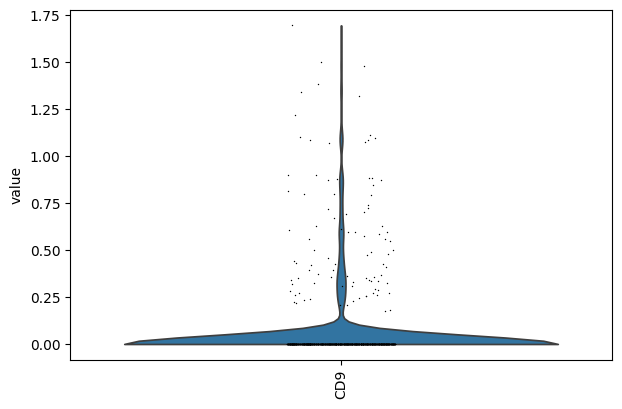

In [120]:
import scanpy as sc

sc.pl.violin(
    mac_adata,
    keys='CD9',
    rotation=90
)

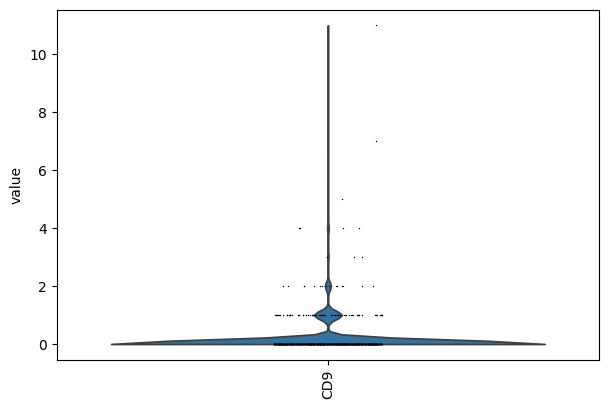

In [121]:
import scanpy as sc

sc.pl.violin(
    mac_adata,
    keys='CD9',
    rotation=90,
    layer='counts'
)

In [122]:
gene_idx = mac_adata.var_names.get_loc('CD9')
counts = mac_adata.layers["counts"][:, gene_idx]

# If sparse matrix (very likely in your atlas)
if not isinstance(counts, np.ndarray):
    counts = counts.toarray().flatten()

In [123]:
n_positive = np.sum(counts > 0)
n_total = mac_adata.n_obs
percent_positive = n_positive / n_total * 100

n_positive, n_total, percent_positive

(95, 1172, 8.10580204778157)

In [126]:
n_positive = np.sum(counts > 1)
n_total = mac_adata.n_obs
percent_positive = n_positive / n_total * 100

n_positive, n_total, percent_positive

(25, 1172, 2.1331058020477816)

In [128]:

mac_adata.obs['CD9_expr'] = mac_adata[:, 'CD9'].X.toarray().flatten()
mac_adata[mac_adata.obs['CD9_expr'] > 0]
mac_adata.obs['CD9_expr'] = mac_adata[:, 'CD9'].X.toarray().flatten()

# Add label column based on expression
mac_adata.obs['CD9_label'] = np.where(mac_adata.obs['CD9_expr'] > 0, 'CD9+', 'CD9-')

In [ ]:
mye_clr_pr['mye_anno']=myeloid_adata.obs['mye_anno'].tolist()

In [131]:
mac_clr_pr = mye_clr_pr[~mye_clr_pr["mye_anno"].isin(['cDC2','cDC1','CCR7+ DC','Neutrophil'])]

In [ ]:
mac_clr_pr

In [ ]:
mac_adata.obs

In [135]:
mac_clr_pr["cd9_anno"]=mac_adata.obs['CD9_label'].tolist()

In [136]:
mac_clr_pr["cd9_anno"].value_counts()

cd9_anno
CD9-    1077
CD9+      95
Name: count, dtype: int64

In [140]:
mac_clr_pr_clean = mac_clr_pr.drop(['anno','mye_anno'],axis =1)
mac_clr_pr_clean

,anti-human_CD86,anti-human_CD274_B7-H1_PD-L1,anti-human_CD270_HVEM_TR2,anti-human_CD155_PVR,anti-human_CD112_Nectin-2,anti-human_CD47,anti-human_CD48,anti-human_CD40,anti-human_CD154,anti-human_CD52,...,anti-human_CD23,anti-human_Ig_light_chain_L,anti-human_CD328_Siglec-7,anti-human_GPR56,anti-human_HLA-E,anti-human_CD82,anti-human_CD101_BB27,anti-human_CD88_C5aR,anti-human_CD224,cd9_anno
AACTCAGGTGTGCGTC-1-0,-0.471457,0.914837,2.093492,2.093492,1.474453,3.922992,3.378690,0.221690,1.607984,1.725767,...,1.607984,1.320302,0.914837,0.221690,2.093492,3.054903,0.221690,1.320302,1.607984,CD9-
AACTGGTCAGGTCGTC-1-0,1.617292,1.617292,3.003586,2.715904,1.617292,3.814516,3.226730,1.617292,2.715904,-2.987878,...,3.003586,2.310439,-2.987878,-2.987878,-2.987878,3.919877,-2.987878,-2.987878,3.226730,CD9-
AATCCAGAGCTACCGC-1-0,2.407751,1.309139,3.100898,2.002286,2.407751,5.316472,4.444633,-3.296031,2.918577,1.309139,...,2.695433,2.407751,3.100898,1.309139,-3.296031,3.388581,-3.296031,1.309139,2.002286,CD9-
ACTTGTTCAGATGGCA-1-0,-4.188523,0.416647,2.208406,0.416647,1.802941,3.594701,4.510991,1.109794,2.208406,2.208406,...,1.109794,1.515259,0.416647,1.802941,0.416647,3.124697,-4.188523,1.515259,2.719232,CD9-
AGAATAGCACGGCGTT-1-0,0.346298,1.732593,1.039445,0.346298,1.732593,4.238119,4.130488,1.039445,2.744194,2.138058,...,1.039445,1.955736,2.138058,0.346298,1.039445,3.565174,0.346298,1.732593,4.800646,CD9-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGCCGTCATTCTTAC-1-11,-0.143755,0.261710,0.261710,0.261710,1.242539,2.298592,2.421194,1.242539,1.871148,1.109008,...,1.242539,0.772535,1.360322,0.261710,0.772535,2.458934,-0.143755,0.954857,2.597085,CD9-
TTGGAACAGTGTTGAA-1-11,-0.830666,1.808391,0.555628,0.555628,0.267946,2.858213,2.113773,1.808391,1.808391,0.555628,...,-0.137519,0.961093,2.806920,0.267946,1.366558,1.734283,0.267946,0.555628,3.723211,CD9+
TTGGAACCAGCTATTG-1-11,1.958512,1.506527,1.352376,0.946911,2.045523,2.961814,3.274189,1.757841,1.506527,1.640058,...,1.640058,1.352376,2.450988,-5.044553,0.659229,2.556349,0.659229,1.757841,3.321817,CD9-
TTTGCGCTCACCTTAT-1-11,0.456588,1.044375,1.149735,1.149735,1.680363,2.631340,3.421861,1.245045,-0.459703,0.638910,...,0.793060,1.245045,2.214446,-0.054238,1.245045,2.924688,-1.152850,0.233444,3.151215,CD9-


In [141]:
groups = mac_clr_pr_clean['cd9_anno'].unique()
groups

array(['CD9-', 'CD9+'], dtype=object)

In [142]:
mac_clr_pr_clean

,anti-human_CD86,anti-human_CD274_B7-H1_PD-L1,anti-human_CD270_HVEM_TR2,anti-human_CD155_PVR,anti-human_CD112_Nectin-2,anti-human_CD47,anti-human_CD48,anti-human_CD40,anti-human_CD154,anti-human_CD52,...,anti-human_CD23,anti-human_Ig_light_chain_L,anti-human_CD328_Siglec-7,anti-human_GPR56,anti-human_HLA-E,anti-human_CD82,anti-human_CD101_BB27,anti-human_CD88_C5aR,anti-human_CD224,cd9_anno
AACTCAGGTGTGCGTC-1-0,-0.471457,0.914837,2.093492,2.093492,1.474453,3.922992,3.378690,0.221690,1.607984,1.725767,...,1.607984,1.320302,0.914837,0.221690,2.093492,3.054903,0.221690,1.320302,1.607984,CD9-
AACTGGTCAGGTCGTC-1-0,1.617292,1.617292,3.003586,2.715904,1.617292,3.814516,3.226730,1.617292,2.715904,-2.987878,...,3.003586,2.310439,-2.987878,-2.987878,-2.987878,3.919877,-2.987878,-2.987878,3.226730,CD9-
AATCCAGAGCTACCGC-1-0,2.407751,1.309139,3.100898,2.002286,2.407751,5.316472,4.444633,-3.296031,2.918577,1.309139,...,2.695433,2.407751,3.100898,1.309139,-3.296031,3.388581,-3.296031,1.309139,2.002286,CD9-
ACTTGTTCAGATGGCA-1-0,-4.188523,0.416647,2.208406,0.416647,1.802941,3.594701,4.510991,1.109794,2.208406,2.208406,...,1.109794,1.515259,0.416647,1.802941,0.416647,3.124697,-4.188523,1.515259,2.719232,CD9-
AGAATAGCACGGCGTT-1-0,0.346298,1.732593,1.039445,0.346298,1.732593,4.238119,4.130488,1.039445,2.744194,2.138058,...,1.039445,1.955736,2.138058,0.346298,1.039445,3.565174,0.346298,1.732593,4.800646,CD9-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGCCGTCATTCTTAC-1-11,-0.143755,0.261710,0.261710,0.261710,1.242539,2.298592,2.421194,1.242539,1.871148,1.109008,...,1.242539,0.772535,1.360322,0.261710,0.772535,2.458934,-0.143755,0.954857,2.597085,CD9-
TTGGAACAGTGTTGAA-1-11,-0.830666,1.808391,0.555628,0.555628,0.267946,2.858213,2.113773,1.808391,1.808391,0.555628,...,-0.137519,0.961093,2.806920,0.267946,1.366558,1.734283,0.267946,0.555628,3.723211,CD9+
TTGGAACCAGCTATTG-1-11,1.958512,1.506527,1.352376,0.946911,2.045523,2.961814,3.274189,1.757841,1.506527,1.640058,...,1.640058,1.352376,2.450988,-5.044553,0.659229,2.556349,0.659229,1.757841,3.321817,CD9-
TTTGCGCTCACCTTAT-1-11,0.456588,1.044375,1.149735,1.149735,1.680363,2.631340,3.421861,1.245045,-0.459703,0.638910,...,0.793060,1.245045,2.214446,-0.054238,1.245045,2.924688,-1.152850,0.233444,3.151215,CD9-


In [143]:

# Define custom colors
group_colors = {'CD9+': 'tomato', 'CD9-': 'steelblue'}

# Define significance level thresholds
def get_significance_stars(pval):
    if pval < 0.001:
        return '***'
    elif pval < 0.01:
        return '**'
    elif pval < 0.05:
        return '*'
    else:
        return 'ns'


In [144]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

def mann_whitney_u_test(df, group_col, value_cols):
    """
    Perform Mann-Whitney U test for each protein between two groups and adjust for multiple testing.

    Parameters:
    - df (pd.DataFrame): Dataframe containing values and group labels.
    - group_col (str): Column name representing the groups.
    - value_cols (list of str): Column names representing the numerical values (proteins).
    
    Returns:
    - pd.DataFrame: Dataframe with proteins, p-values, and adjusted p-values.
    """
    results = []
    groups = df[group_col].unique()
    
    # Ensure there are only two groups
    if len(groups) != 2:
        raise ValueError("This method requires exactly two groups for comparison.")
    
    group1_data = df[df[group_col] == groups[0]]
    group2_data = df[df[group_col] == groups[1]]
    
    # Perform Mann-Whitney U test for each protein
    for protein in value_cols:
        group1_values = group1_data[protein].dropna()
        group2_values = group2_data[protein].dropna()
        
        # Mann-Whitney U test
        stat, p_value = mannwhitneyu(group1_values, group2_values, alternative='two-sided')
        
        # Append result (protein name, p-value)
        results.append((protein, p_value))
    
    # Convert to DataFrame
    result_df = pd.DataFrame(results, columns=["Protein", "p_value"])
    
    # Adjust p-values for multiple comparisons (Benjamini-Hochberg)
    result_df["p_value_adj"] = multipletests(result_df["p_value"], method='fdr_bh')[1]
    
    # Sort by adjusted p-value
    result_df = result_df.sort_values(by="p_value_adj")
    
    return result_df

# Example usage:
protein_columns = mac_clr_pr_clean.columns.difference(["cd9_anno"])  # Exclude the group column
mann_whitney_results = mann_whitney_u_test(mac_clr_pr_clean, group_col="cd9_anno", value_cols=protein_columns)



In [145]:
mann_whitney_results[mann_whitney_results['p_value_adj']<=0.1].shape

(31, 3)

In [146]:
mann_whitney_results_sig = mann_whitney_results[mann_whitney_results['p_value_adj']<=0.1]
mann_whitney_results_sig

,Protein,p_value,p_value_adj
52,anti-human_CD223_LAG-3,9.950265e-09,0.000001
111,anti-human_CD82,8.758633e-07,0.000060
108,anti-human_CD79b_IgB,2.719580e-06,0.000124
63,anti-human_CD270_HVEM_TR2,5.978715e-06,0.000205
91,anti-human_CD48,3.490693e-05,0.000956
112,anti-human_CD83,5.019292e-05,0.001146
127,anti-human_IgM,1.222334e-04,0.002392
115,anti-human_CD88_C5aR,2.465744e-04,0.004223
90,anti-human_CD47,2.968373e-04,0.004519
55,anti-human_CD23,4.069821e-04,0.005576


In [147]:
mac_clr_pr_clean_sig = mac_clr_pr_clean[mann_whitney_results_sig['Protein'].tolist()]
mac_clr_pr_clean_sig['cd9_anno']=mac_clr_pr_clean['cd9_anno'].tolist()

In [148]:
import numpy as np
import pandas as pd
from scipy import stats

def cohen_d(group1, group2):
    """
    Compute Cohen's d for two groups.
    """
    mean1 = np.mean(group1)
    mean2 = np.mean(group2)
    var1 = np.var(group1, ddof=1)
    var2 = np.var(group2, ddof=1)
    pooled_std = np.sqrt((var1 + var2) / 2)
    return (mean1 - mean2) / pooled_std

def compute_cohen_d(df, group_col, value_cols):
    """
    Compute Cohen's d for each protein between two groups.

    Parameters:
    - df (pd.DataFrame): Dataframe containing values and group labels.
    - group_col (str): Column name representing the groups.
    - value_cols (list of str): Column names representing the numerical values (proteins).
    
    Returns:
    - pd.DataFrame: Dataframe with proteins and their Cohen's d values.
    """
    results = []
    groups = df[group_col].unique()
    
    # Ensure there are only two groups
    if len(groups) != 2:
        raise ValueError("This method requires exactly two groups for comparison.")
    
    group1_data = df[df[group_col] == groups[0]]
    group2_data = df[df[group_col] == groups[1]]
    
    # Compute Cohen's d for each protein
    for protein in value_cols:
        group1_values = group1_data[protein].dropna()
        group2_values = group2_data[protein].dropna()
        d_value = cohen_d(group1_values, group2_values)
        results.append((protein, d_value))
    
    # Convert to DataFrame and sort by effect size
    result_df = pd.DataFrame(results, columns=["Protein", "Cohen_d"]).sort_values(by="Cohen_d", ascending=False)
    
    return result_df

# Example usage:
protein_columns = mac_clr_pr_clean_sig.columns.difference(["cd9_anno"])  # Exclude the group column
cohen_d_results = compute_cohen_d(mac_clr_pr_clean_sig, group_col="cd9_anno", value_cols=protein_columns)


In [149]:

# Display top proteins with highest Cohen's d values
cohen_d_results_effect = cohen_d_results[(cohen_d_results['Cohen_d']>=0.2)|(cohen_d_results['Cohen_d']<=-0.2)]
cohen_d_results_effect.shape

(18, 2)

In [150]:
cohen_d_results_effect=cohen_d_results_effect.sort_values(by="Cohen_d", key=abs, ascending=False)
cohen_d_results_effect

,Protein,Cohen_d
26,anti-human_CD82,0.555657
11,anti-human_CD223_LAG-3,0.523315
17,anti-human_CD270_HVEM_TR2,0.433705
22,anti-human_CD48,0.415955
27,anti-human_CD83,0.411784
25,anti-human_CD79b_IgB,0.356367
6,anti-human_CD154,0.351336
21,anti-human_CD47,0.350979
13,anti-human_CD23,0.299847
9,anti-human_CD194_CCR4,0.296505


In [151]:
heatmap_data = mac_clr_pr_clean_sig.groupby("cd9_anno").mean(numeric_only=True).T

In [152]:
heatmap_data

cd9_anno,CD9+,CD9-
anti-human_CD223_LAG-3,1.201191,1.585766
anti-human_CD82,2.184525,2.520141
anti-human_CD79b_IgB,0.320887,0.718772
anti-human_CD270_HVEM_TR2,0.945781,1.357755
anti-human_CD48,2.488978,2.851385
anti-human_CD83,1.632037,1.875613
anti-human_IgM,-0.327042,0.056215
anti-human_CD88_C5aR,0.898343,1.024969
anti-human_CD47,2.828464,3.070035
anti-human_CD23,1.064996,1.322376


In [153]:
heatmap_data=heatmap_data[heatmap_data.index.isin(cohen_d_results_effect['Protein'].tolist())]
heatmap_data

cd9_anno,CD9+,CD9-
anti-human_CD223_LAG-3,1.201191,1.585766
anti-human_CD82,2.184525,2.520141
anti-human_CD79b_IgB,0.320887,0.718772
anti-human_CD270_HVEM_TR2,0.945781,1.357755
anti-human_CD48,2.488978,2.851385
anti-human_CD83,1.632037,1.875613
anti-human_IgM,-0.327042,0.056215
anti-human_CD47,2.828464,3.070035
anti-human_CD23,1.064996,1.322376
anti-human_CD154,1.282939,1.535168


In [154]:
new_ind = []
for i in heatmap_data.index.tolist():
    if 'anti-human' in i:
        new_ind.append(i.split('anti-human_')[1])
    else:
        new_ind.append(i.split('anti-mouse-human_')[1])

In [155]:
heatmap_data.index = new_ind

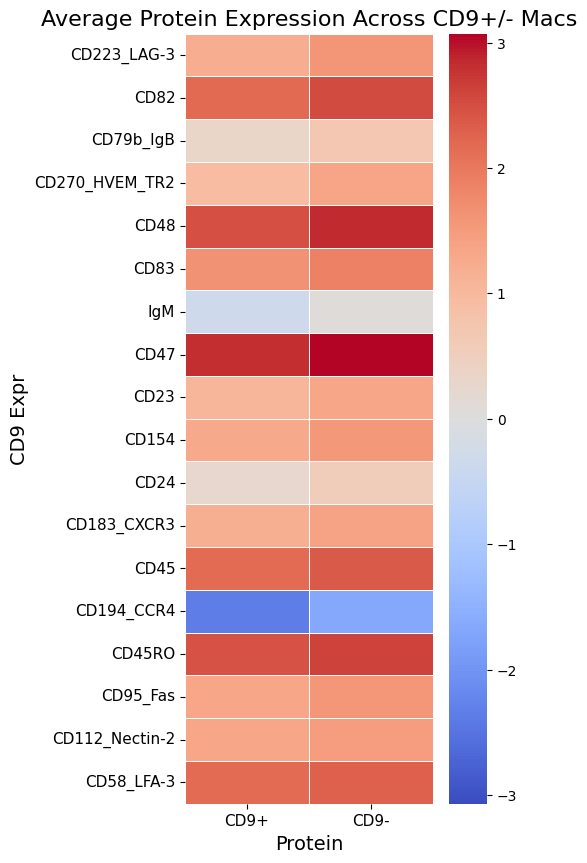

In [156]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Plot the heatmap with blue-to-red color scale
plt.figure(figsize=(4, 10))  # Adjust figure size for better readability

# Use vmin and vmax to center the color scale around 0
sns.heatmap(heatmap_data, cmap="coolwarm", linewidths=0.5, xticklabels=True, yticklabels=True,
            vmin=-heatmap_data.max().max(), vmax=heatmap_data.max().max())  # Center color scale at 0

# Customize labels
plt.xlabel("Protein", fontsize=14)  # Now the x-axis represents proteins
plt.ylabel("CD9 Expr", fontsize=14)  # Now the y-axis represents cell types
plt.title("Average Protein Expression Across CD9+/- Macs", fontsize=16)

# Increase font size for x and y axis tick marks
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Save to PDF
plt.savefig("cd9_mac_top_diff_prs.pdf", format="pdf", bbox_inches="tight")

# Display the plot
plt.show()


In [158]:
mac_clr_pr_clean_sig_cohen = mac_clr_pr_clean_sig[cohen_d_results_effect['Protein'].tolist()]
mac_clr_pr_clean_sig_cohen['anno']= mac_clr_pr_clean_sig['cd9_anno'].tolist()
mac_clr_pr_clean_sig_cohen

,anti-human_CD82,anti-human_CD223_LAG-3,anti-human_CD270_HVEM_TR2,anti-human_CD48,anti-human_CD83,anti-human_CD79b_IgB,anti-human_CD154,anti-human_CD47,anti-human_CD23,anti-human_CD194_CCR4,anti-human_CD45RO,anti-human_CD45,anti-human_CD58_LFA-3,anti-human_CD183_CXCR3,anti-human_IgM,anti-human_CD95_Fas,anti-human_CD24,anti-human_CD112_Nectin-2,anno
AACTCAGGTGTGCGTC-1-0,3.054903,1.926438,2.093492,3.378690,2.093492,0.914837,1.607984,3.922992,1.607984,-0.471457,2.524275,2.013450,2.361756,1.831128,0.627155,3.846031,1.137981,1.474453,CD9-
AACTGGTCAGGTCGTC-1-0,3.919877,2.715904,3.003586,3.226730,2.715904,2.715904,2.715904,3.814516,3.003586,1.617292,3.409051,2.310439,-2.987878,1.617292,1.617292,3.003586,1.617292,1.617292,CD9-
AATCCAGAGCTACCGC-1-0,3.388581,2.407751,3.100898,4.444633,1.309139,-3.296031,2.918577,5.316472,2.695433,-3.296031,3.388581,2.407751,3.255049,2.002286,-3.296031,1.309139,-3.296031,2.407751,CD9-
ACTTGTTCAGATGGCA-1-0,3.124697,2.362557,2.208406,4.510991,2.719232,1.515259,2.208406,3.594701,1.109794,-4.188523,3.249860,3.307019,2.208406,1.515259,0.416647,2.496088,1.515259,1.802941,CD9-
AGAATAGCACGGCGTT-1-0,3.565174,1.732593,1.039445,4.130488,2.292208,1.444911,2.744194,4.238119,1.039445,-4.258872,3.179512,3.179512,2.138058,1.039445,2.911248,3.054348,1.039445,1.732593,CD9-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGCCGTCATTCTTAC-1-11,2.458934,1.465683,0.261710,2.421194,1.871148,0.772535,1.871148,2.298592,1.242539,0.549392,2.107537,1.871148,1.871148,1.360322,-0.143755,1.648004,0.772535,1.242539,CD9-
TTGGAACAGTGTTGAA-1-11,1.734283,2.002547,0.555628,2.113773,1.877384,0.267946,1.808391,2.858213,-0.137519,0.555628,2.304828,1.567229,2.780252,2.113773,0.267946,0.961093,0.778772,0.267946,CD9+
TTGGAACCAGCTATTG-1-11,2.556349,1.506527,1.352376,3.274189,1.170055,0.946911,1.506527,2.961814,1.640058,-0.439383,2.856454,2.818713,2.505056,0.253764,0.253764,3.086977,0.946911,2.045523,CD9-
TTTGCGCTCACCTTAT-1-11,2.924688,0.793060,1.149735,3.421861,1.555200,-1.152850,-0.459703,2.631340,0.793060,-1.152850,2.890201,2.179355,2.560722,1.412099,-1.152850,2.458068,1.044375,1.680363,CD9-


In [159]:
mann_whitney_results_sig_cohen = mann_whitney_results_sig[mann_whitney_results_sig['Protein'].isin(cohen_d_results_effect['Protein'].tolist())]
mann_whitney_results_sig_cohen

,Protein,p_value,p_value_adj
52,anti-human_CD223_LAG-3,9.950265e-09,0.000001
111,anti-human_CD82,8.758633e-07,0.000060
108,anti-human_CD79b_IgB,2.719580e-06,0.000124
63,anti-human_CD270_HVEM_TR2,5.978715e-06,0.000205
91,anti-human_CD48,3.490693e-05,0.000956
112,anti-human_CD83,5.019292e-05,0.001146
127,anti-human_IgM,1.222334e-04,0.002392
90,anti-human_CD47,2.968373e-04,0.004519
55,anti-human_CD23,4.069821e-04,0.005576
30,anti-human_CD154,5.076258e-04,0.006322


In [217]:

subset =mann_whitney_results_sig_cohen['Protein'].tolist()[:12]
len(subset)

12

In [218]:
mann_whitney_results_sig_cohen_subset = mann_whitney_results_sig_cohen[mann_whitney_results_sig_cohen['Protein'].isin(subset)]
mann_whitney_results_sig_cohen_subset

,Protein,p_value,p_value_adj
52,anti-human_CD223_LAG-3,9.950265e-09,0.000001
111,anti-human_CD82,8.758633e-07,0.000060
108,anti-human_CD79b_IgB,2.719580e-06,0.000124
63,anti-human_CD270_HVEM_TR2,5.978715e-06,0.000205
91,anti-human_CD48,3.490693e-05,0.000956
112,anti-human_CD83,5.019292e-05,0.001146
127,anti-human_IgM,1.222334e-04,0.002392
90,anti-human_CD47,2.968373e-04,0.004519
55,anti-human_CD23,4.069821e-04,0.005576
30,anti-human_CD154,5.076258e-04,0.006322


In [219]:
cohen_d_results_effect_subset = cohen_d_results_effect[cohen_d_results_effect['Protein'].isin(subset)]
cohen_d_results_effect_subset

,Protein,Cohen_d
26,anti-human_CD82,0.555657
11,anti-human_CD223_LAG-3,0.523315
17,anti-human_CD270_HVEM_TR2,0.433705
22,anti-human_CD48,0.415955
27,anti-human_CD83,0.411784
25,anti-human_CD79b_IgB,0.356367
6,anti-human_CD154,0.351336
21,anti-human_CD47,0.350979
13,anti-human_CD23,0.299847
8,anti-human_CD183_CXCR3,0.260948


In [220]:
mac_clr_pr_clean_sig_cohen

,anti-human_CD82,anti-human_CD223_LAG-3,anti-human_CD270_HVEM_TR2,anti-human_CD48,anti-human_CD83,anti-human_CD79b_IgB,anti-human_CD154,anti-human_CD47,anti-human_CD23,anti-human_CD194_CCR4,anti-human_CD45RO,anti-human_CD45,anti-human_CD58_LFA-3,anti-human_CD183_CXCR3,anti-human_IgM,anti-human_CD95_Fas,anti-human_CD24,anti-human_CD112_Nectin-2,anno
AACTCAGGTGTGCGTC-1-0,3.054903,1.926438,2.093492,3.378690,2.093492,0.914837,1.607984,3.922992,1.607984,-0.471457,2.524275,2.013450,2.361756,1.831128,0.627155,3.846031,1.137981,1.474453,CD9-
AACTGGTCAGGTCGTC-1-0,3.919877,2.715904,3.003586,3.226730,2.715904,2.715904,2.715904,3.814516,3.003586,1.617292,3.409051,2.310439,-2.987878,1.617292,1.617292,3.003586,1.617292,1.617292,CD9-
AATCCAGAGCTACCGC-1-0,3.388581,2.407751,3.100898,4.444633,1.309139,-3.296031,2.918577,5.316472,2.695433,-3.296031,3.388581,2.407751,3.255049,2.002286,-3.296031,1.309139,-3.296031,2.407751,CD9-
ACTTGTTCAGATGGCA-1-0,3.124697,2.362557,2.208406,4.510991,2.719232,1.515259,2.208406,3.594701,1.109794,-4.188523,3.249860,3.307019,2.208406,1.515259,0.416647,2.496088,1.515259,1.802941,CD9-
AGAATAGCACGGCGTT-1-0,3.565174,1.732593,1.039445,4.130488,2.292208,1.444911,2.744194,4.238119,1.039445,-4.258872,3.179512,3.179512,2.138058,1.039445,2.911248,3.054348,1.039445,1.732593,CD9-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGCCGTCATTCTTAC-1-11,2.458934,1.465683,0.261710,2.421194,1.871148,0.772535,1.871148,2.298592,1.242539,0.549392,2.107537,1.871148,1.871148,1.360322,-0.143755,1.648004,0.772535,1.242539,CD9-
TTGGAACAGTGTTGAA-1-11,1.734283,2.002547,0.555628,2.113773,1.877384,0.267946,1.808391,2.858213,-0.137519,0.555628,2.304828,1.567229,2.780252,2.113773,0.267946,0.961093,0.778772,0.267946,CD9+
TTGGAACCAGCTATTG-1-11,2.556349,1.506527,1.352376,3.274189,1.170055,0.946911,1.506527,2.961814,1.640058,-0.439383,2.856454,2.818713,2.505056,0.253764,0.253764,3.086977,0.946911,2.045523,CD9-
TTTGCGCTCACCTTAT-1-11,2.924688,0.793060,1.149735,3.421861,1.555200,-1.152850,-0.459703,2.631340,0.793060,-1.152850,2.890201,2.179355,2.560722,1.412099,-1.152850,2.458068,1.044375,1.680363,CD9-


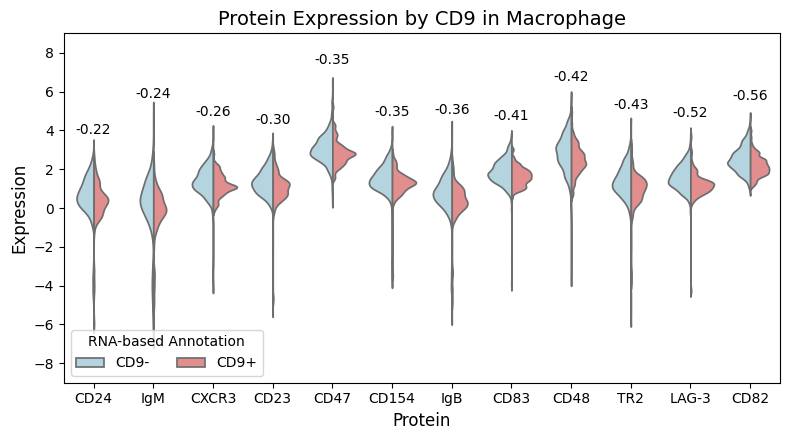

In [223]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd



# Ensure proteins are sorted by p-value (ascending order)
sorted_proteins = cohen_d_results_effect_subset[cohen_d_results_effect_subset['Protein'].isin(subset)]["Protein"].tolist()[::-1]

# Convert data to long format for violin plot
df_long = mac_clr_pr_clean_sig_cohen.melt(id_vars=["anno"], var_name="Protein", value_name="Expression")

# Filter to keep only the sorted proteins
df_long = df_long[df_long["Protein"].isin(sorted_proteins)]
df_long["Protein"] = pd.Categorical(df_long["Protein"], categories=sorted_proteins, ordered=True)  # Ensure correct order

# Create a custom palette for coloring the annotation groups
palette = {"CD9+": "#f08080", "CD9-": "#add8e6"}  # Assign colors

# Create violin plot with smaller bandwidth to reduce rectangle size
plt.figure(figsize=(8, 4.5))
ax = sns.violinplot(x="Protein", y="Expression", hue="anno", data=df_long, split=True, palette=palette, bw=0.2, inner=None)

# Add Cohen's d values
for i, protein in enumerate(sorted_proteins):
    p_value = mann_whitney_results_sig_cohen_subset.loc[mann_whitney_results_sig_cohen_subset["Protein"] == protein, "p_value_adj"].values[0]
    cohen_d = -cohen_d_results_effect_subset.loc[cohen_d_results_effect_subset["Protein"] == protein, "Cohen_d"].values[0]
    
    # Get y-position for annotation
    y_max = df_long.loc[df_long["Protein"] == protein, "Expression"].max()
    y_spacing = (y_max - df_long["Expression"].min()) * 0.065  # Adjust spacing

    # Add Cohen's d label above the violin plot
    plt.text(i, y_max + y_spacing, f"{cohen_d:.2f}", ha="center", va="bottom", fontsize=10)


# Customizing x-axis tick labels to use the last part after splitting by '_'
new_labels = [i.split('_')[-1] for i in sorted_proteins]
plt.xticks(ticks=range(len(sorted_proteins)), labels=new_labels, fontsize=10)

# Formatting
plt.xlabel("Protein", fontsize=12)
plt.ylabel("Expression", fontsize=12)
plt.ylim(-9, 9)
plt.title("Protein Expression by CD9 in Macrophage", fontsize=14)
plt.legend(title="RNA-based Annotation", loc='lower left', ncol=2)

plt.tight_layout()

plt.show()
